### Time Series Analysis of Network Utilization for Distributed Scientific Workflows
#### Yingxin Deng
#### 2026/10/14

## Peak, spike, lookback, and traffic-regime analysis

This notebook keeps the original hard Structured TCN with raw hit ratio as the primary model. It evaluates whether errors are concentrated on normal days, high-utilization peaks, or sudden spikes; whether longer lookback windows improve peak forecasting; and whether performance changes across traffic regimes.

This first version uses one seed (`42`) and no rolling windows.

### Experimental design

All experiments use one-day-ahead forecasting, five residual blocks, 64 channels per block, and validation hit-size RMSE for checkpoint selection. Lookbacks are 14, 56, and 112 days; all are within the five-block receptive field of 125 days.

- **Early in-regime:** chronological 70/15/15 split within 2020-05-31 to 2021-09-30.
- **Transition cross-regime:** train and validate on the early regime, then test on 2021-10-01 to 2022-06-30. The July–September 2021 early test period is excluded from this experiment.
- **Late in-regime:** chronological 70/15/15 split within 2022-07-01 to 2024-03-31.

Peak and spike thresholds are calculated from each experiment's training targets only. A peak is above the training 90th percentile. A spike is a one-day increase above the training 90th percentile of daily increases.

### 1. Load data and define chronological traffic-regime experiments

In [1]:
from pathlib import Path
import copy
import random
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
LOOKBACKS = [14, 56, 112]
FEATURE_NAMES = ['access_count', 'access_size', 'hit_count', 'hit_size', 'miss_count', 'miss_size']
PRIMARY_INDEX = FEATURE_NAMES.index('hit_size')
CHANNELS, KERNEL_SIZE, DROPOUT = (64, 64, 64, 64, 64), 3, 0.1
MAX_EPOCHS, PATIENCE, BATCH_SIZE, LEARNING_RATE = 60, 10, 32, 1e-3
PEAK_QUANTILE, SPIKE_QUANTILE = 0.90, 0.90
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

data_dirs = [Path('../xcache-ts-df'), Path('../xcache-ts/pickled_data/df'), Path('xcache-ts-df'), Path('xcache-ts/pickled_data/df')]
data_file = next((directory / 'socal-2006-2403-daily-ml' for directory in data_dirs if (directory / 'socal-2006-2403-daily-ml').is_file()), None)
if data_file is None: raise FileNotFoundError('Cannot find the SoCal daily data file.')
df = pd.read_pickle(data_file).loc['2020-05-31':'2024-03-31', FEATURE_NAMES].copy()
df[['access_size', 'hit_size', 'miss_size']] /= 1000 ** 4
assert df.index.equals(pd.date_range('2020-05-31', '2024-03-31', freq='D')) and len(df) == 1401
np.testing.assert_allclose(df['access_count'], df['hit_count'] + df['miss_count'])
np.testing.assert_allclose(df['access_size'], df['hit_size'] + df['miss_size'])
raw_values = df.to_numpy(dtype=np.float32)
date_to_position = pd.Series(np.arange(len(df)), index=df.index)

def within_regime_split(start, end):
    dates = pd.date_range(start, end, freq='D')
    train_rows, validation_rows = int(0.70 * len(dates)), int(0.15 * len(dates))
    return {
        'train_start': dates[0], 'train_end': dates[train_rows - 1],
        'validation_start': dates[train_rows], 'validation_end': dates[train_rows + validation_rows - 1],
        'test_start': dates[train_rows + validation_rows], 'test_end': dates[-1],
    }

early_split = within_regime_split('2020-05-31', '2021-09-30')
late_split = within_regime_split('2022-07-01', '2024-03-31')
regimes = {
    'Early in-regime': early_split,
    'Transition cross-regime': {**early_split, 'test_start': pd.Timestamp('2021-10-01'), 'test_end': pd.Timestamp('2022-06-30')},
    'Late in-regime': late_split,
}

split_rows = []
for name, split in regimes.items():
    for subset in ['train', 'validation', 'test']:
        split_rows.append({'experiment': name, 'subset': subset.title(), 'first target': split[f'{subset}_start'].date(), 'last target': split[f'{subset}_end'].date(), 'days': len(pd.date_range(split[f'{subset}_start'], split[f'{subset}_end']))})
display(pd.DataFrame(split_rows))



A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/traitlets/config/application.py", line 1082, in launch_instance
    app.start()
  File "/Library/Frameworks/Python.framework/Versions/3.11/lib/python3.11/site-packages/ipyk

,experiment,subset,first target,last target,days
0,Early in-regime,Train,2020-05-31,2021-05-06,341
1,Early in-regime,Validation,2021-05-07,2021-07-18,73
2,Early in-regime,Test,2021-07-19,2021-09-30,74
3,Transition cross-regime,Train,2020-05-31,2021-05-06,341
4,Transition cross-regime,Validation,2021-05-07,2021-07-18,73
5,Transition cross-regime,Test,2021-10-01,2022-06-30,273
6,Late in-regime,Train,2022-07-01,2023-09-21,448
7,Late in-regime,Validation,2023-09-22,2023-12-26,96
8,Late in-regime,Test,2023-12-27,2024-03-31,96


### 2. Define the hard Structured TCN and evaluation helpers

The model predicts log-access and raw hit ratio, then reconstructs hit and miss. Therefore every forecast has non-negative miss and exactly satisfies `access = hit + miss`.

In [2]:
class Chomp1d(nn.Module):
    def __init__(self, size): super().__init__(); self.size = size
    def forward(self, x): return x[:, :, :-self.size].contiguous() if self.size else x

class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, dilation):
        super().__init__(); padding = (KERNEL_SIZE - 1) * dilation
        self.net = nn.Sequential(nn.Conv1d(in_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT), nn.Conv1d(out_channels, out_channels, KERNEL_SIZE, padding=padding, dilation=dilation), Chomp1d(padding), nn.ReLU(), nn.Dropout(DROPOUT))
        self.residual = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else nn.Identity()
    def forward(self, x): return torch.relu(self.net(x) + self.residual(x))

class StructuredTCN(nn.Module):
    def __init__(self):
        super().__init__(); blocks, in_channels = [], 4
        for level, out_channels in enumerate(CHANNELS):
            blocks.append(TemporalBlock(in_channels, out_channels, 2 ** level)); in_channels = out_channels
        self.tcn = nn.Sequential(*blocks); self.output = nn.Linear(CHANNELS[-1], 4)
    def forward(self, x):
        output = self.output(self.tcn(x)[:, :, -1])
        return torch.cat([output[:, :2], torch.sigmoid(output[:, 2:])], dim=1)

def make_loader(x, y, shuffle=False):
    return DataLoader(TensorDataset(torch.tensor(x.transpose(0, 2, 1).tolist(), dtype=torch.float32), torch.tensor(y.tolist(), dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=shuffle)

def structured_loss(prediction, target):
    return nn.functional.mse_loss(prediction[:, :2], target[:, :2]) + 5 * nn.functional.mse_loss(prediction[:, 2:], target[:, 2:])

def binary_metrics(actual_event, predicted_event):
    true_positive = int(np.sum(actual_event & predicted_event))
    precision = true_positive / max(int(predicted_event.sum()), 1)
    recall = true_positive / max(int(actual_event.sum()), 1)
    return precision, recall


### 3. Train all regime × lookback experiments and evaluate normal days, peaks, and spikes

This cell runs 9 fits: three lookbacks in each of three traffic-regime experiments. For access size and hit size, it reports overall, normal-day, peak-day, and spike-day RMSE/MAE/bias. Peak and spike detection precision/recall use thresholds estimated only from the relevant training period.

In [3]:
def train_and_evaluate(experiment_name, split, lookback):
    train_positions = date_to_position.loc[split['train_start']:split['train_end']].to_numpy()
    validation_positions = date_to_position.loc[split['validation_start']:split['validation_end']].to_numpy()
    test_positions = date_to_position.loc[split['test_start']:split['test_end']].to_numpy()
    train_positions = train_positions[train_positions >= lookback]
    validation_positions = validation_positions[validation_positions >= lookback]
    test_positions = test_positions[test_positions >= lookback]

    count_ratio = np.divide(raw_values[:, 2], raw_values[:, 0], out=np.zeros(len(df)), where=raw_values[:, 0] > 0)
    size_ratio = np.divide(raw_values[:, 3], raw_values[:, 1], out=np.zeros(len(df)), where=raw_values[:, 1] > 0)
    structured_values = np.column_stack([np.log1p(raw_values[:, 0]), np.log1p(raw_values[:, 1]), count_ratio, size_ratio]).astype(np.float32)
    train_raw_positions = date_to_position.loc[split['train_start']:split['train_end']].to_numpy()
    input_scaler = StandardScaler().fit(structured_values[train_raw_positions])
    log_target_scaler = StandardScaler().fit(structured_values[train_raw_positions, :2])
    inputs = input_scaler.transform(structured_values).astype(np.float32)
    labels_all = np.column_stack([log_target_scaler.transform(structured_values[:, :2]), structured_values[:, 2:]]).astype(np.float32)
    def make_features(target_positions): return np.asarray([inputs[position - lookback:position] for position in target_positions], dtype=np.float32)
    x_train, y_train = make_features(train_positions), labels_all[train_positions]
    x_validation, y_validation = make_features(validation_positions), labels_all[validation_positions]
    x_test = make_features(test_positions)

    def predict_original(model, x):
        model.eval(); batches = []
        with torch.no_grad():
            for start in range(0, len(x), BATCH_SIZE):
                tensor = torch.tensor(x[start:start + BATCH_SIZE].transpose(0, 2, 1).tolist(), dtype=torch.float32).to(device)
                batches.append(model(tensor).cpu().tolist())
        output = np.asarray([row for batch in batches for row in batch], dtype=np.float64)
        access = np.maximum(np.expm1(log_target_scaler.inverse_transform(output[:, :2])), 0)
        ratio = np.clip(output[:, 2:], 0, 1)
        return np.column_stack([access[:, 0], access[:, 1], access[:, 0] * ratio[:, 0], access[:, 1] * ratio[:, 1], access[:, 0] * (1 - ratio[:, 0]), access[:, 1] * (1 - ratio[:, 1])])

    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    model = StructuredTCN().to(device); optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    train_loader = make_loader(x_train, y_train, shuffle=True)
    validation_actual = raw_values[validation_positions]
    best_rmse, best_state, best_epoch, stale = float('inf'), None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        for xb, yb in train_loader:
            optimizer.zero_grad(); loss = structured_loss(model(xb.to(device)), yb.to(device)); loss.backward(); optimizer.step()
        validation_prediction = predict_original(model, x_validation)
        validation_rmse = float(np.sqrt(np.mean((validation_prediction[:, PRIMARY_INDEX] - validation_actual[:, PRIMARY_INDEX]) ** 2)))
        if validation_rmse < best_rmse:
            best_rmse, best_state, best_epoch, stale = validation_rmse, copy.deepcopy(model.state_dict()), epoch, 0
        else: stale += 1
        if stale >= PATIENCE: break
    model.load_state_dict(best_state)

    test_prediction = predict_original(model, x_test)
    test_actual = raw_values[test_positions]
    previous_actual = raw_values[test_positions - 1]
    train_actual = raw_values[train_positions]
    train_previous = raw_values[train_positions - 1]
    summary = {'experiment': experiment_name, 'lookback': lookback, 'best_epoch': best_epoch, 'validation_hit_size_rmse': best_rmse, 'test_days': len(test_positions)}
    rows, event_rows = [], []
    for variable, index in [('access_size', 1), ('hit_size', 3)]:
        peak_threshold = np.quantile(train_actual[:, index], PEAK_QUANTILE)
        spike_threshold = np.quantile(train_actual[:, index] - train_previous[:, index], SPIKE_QUANTILE)
        actual_peak, predicted_peak = test_actual[:, index] >= peak_threshold, test_prediction[:, index] >= peak_threshold
        actual_spike = (test_actual[:, index] - previous_actual[:, index]) >= spike_threshold
        predicted_spike = (test_prediction[:, index] - previous_actual[:, index]) >= spike_threshold
        categories = {'Overall': np.ones(len(test_positions), dtype=bool), 'Normal': ~(actual_peak | actual_spike), 'Peak': actual_peak, 'Spike': actual_spike}
        for category, mask in categories.items():
            error = test_prediction[mask, index] - test_actual[mask, index]
            rows.append({'experiment': experiment_name, 'lookback': lookback, 'variable': variable, 'category': category, 'days': int(mask.sum()), 'RMSE': np.sqrt(np.mean(error ** 2)) if len(error) else np.nan, 'MAE': np.mean(np.abs(error)) if len(error) else np.nan, 'Bias': np.mean(error) if len(error) else np.nan, 'unit': 'TB'})
        peak_precision, peak_recall = binary_metrics(actual_peak, predicted_peak)
        spike_precision, spike_recall = binary_metrics(actual_spike, predicted_spike)
        event_rows.append({'experiment': experiment_name, 'lookback': lookback, 'variable': variable, 'event': 'Peak', 'threshold': peak_threshold, 'actual event days': int(actual_peak.sum()), 'predicted event days': int(predicted_peak.sum()), 'precision': peak_precision, 'recall': peak_recall})
        event_rows.append({'experiment': experiment_name, 'lookback': lookback, 'variable': variable, 'event': 'Spike', 'threshold': spike_threshold, 'actual event days': int(actual_spike.sum()), 'predicted event days': int(predicted_spike.sum()), 'precision': spike_precision, 'recall': spike_recall})
    return summary, rows, event_rows

summary_rows, stratified_rows, event_rows = [], [], []
for experiment_name, split in regimes.items():
    for lookback in LOOKBACKS:
        print(f'Running {experiment_name}: {lookback}-day lookback')
        summary, rows, events = train_and_evaluate(experiment_name, split, lookback)
        summary_rows.append(summary); stratified_rows.extend(rows); event_rows.extend(events)

model_summary = pd.DataFrame(summary_rows)
stratified_results = pd.DataFrame(stratified_rows)
event_results = pd.DataFrame(event_rows)
display(model_summary.sort_values(['experiment', 'lookback']))
display(stratified_results)
display(event_results)

week6_dir = Path.cwd() if (Path.cwd() / 'Sammy_TCN_261014.ipynb').exists() else Path.cwd() / 'week6'
output_dir = week6_dir / 'results' / 'peak_spike_regime_analysis'
output_dir.mkdir(parents=True, exist_ok=True)
model_summary.to_csv(output_dir / 'model_selection_summary.csv', index=False)
stratified_results.to_csv(output_dir / 'normal_peak_spike_metrics.csv', index=False)
event_results.to_csv(output_dir / 'peak_spike_detection_metrics.csv', index=False)
print('Saved results to:', output_dir.resolve())


Running Early in-regime: 14-day lookback
Running Early in-regime: 56-day lookback
Running Early in-regime: 112-day lookback
Running Transition cross-regime: 14-day lookback
Running Transition cross-regime: 56-day lookback
Running Transition cross-regime: 112-day lookback
Running Late in-regime: 14-day lookback
Running Late in-regime: 56-day lookback
Running Late in-regime: 112-day lookback


,experiment,lookback,best_epoch,validation_hit_size_rmse,test_days
0,Early in-regime,14,10,4.353442,74
1,Early in-regime,56,8,4.332594,74
2,Early in-regime,112,11,4.240397,74
6,Late in-regime,14,2,18.925008,96
7,Late in-regime,56,13,19.089889,96
8,Late in-regime,112,3,18.771934,96
3,Transition cross-regime,14,10,4.353442,273
4,Transition cross-regime,56,8,4.332594,273
5,Transition cross-regime,112,11,4.240397,273


,experiment,lookback,variable,category,days,RMSE,MAE,Bias,unit
0,Early in-regime,14,access_size,Overall,74,13.342615,9.054968,-1.748774,TB
1,Early in-regime,14,access_size,Normal,63,7.669946,6.036340,2.545540,TB
2,Early in-regime,14,access_size,Peak,9,29.824471,26.247816,-26.247816,TB
3,Early in-regime,14,access_size,Spike,8,33.406299,31.569709,-31.569709,TB
4,Early in-regime,14,hit_size,Overall,74,8.636228,5.611894,-0.537130,TB
...,...,...,...,...,...,...,...,...,...
67,Late in-regime,112,access_size,Spike,14,96.407710,73.252665,-73.252665,TB
68,Late in-regime,112,hit_size,Overall,96,39.964119,20.647496,-5.099605,TB
69,Late in-regime,112,hit_size,Normal,79,14.665928,10.532625,8.200667,TB
70,Late in-regime,112,hit_size,Peak,13,101.050088,79.658229,-78.683805,TB


,experiment,lookback,variable,event,threshold,actual event days,predicted event days,precision,recall
0,Early in-regime,14,access_size,Peak,38.976849,9,1,0.000000,0.000000
1,Early in-regime,14,access_size,Spike,17.823902,8,0,0.000000,0.000000
2,Early in-regime,14,hit_size,Peak,24.822657,6,1,0.000000,0.000000
3,Early in-regime,14,hit_size,Spike,9.116930,7,0,0.000000,0.000000
4,Early in-regime,56,access_size,Peak,36.097908,12,0,0.000000,0.000000
5,Early in-regime,56,access_size,Spike,14.142637,9,0,0.000000,0.000000
6,Early in-regime,56,hit_size,Peak,22.475292,8,1,0.000000,0.000000
7,Early in-regime,56,hit_size,Spike,7.932005,7,0,0.000000,0.000000
8,Early in-regime,112,access_size,Peak,35.951702,12,2,1.000000,0.166667
9,Early in-regime,112,access_size,Spike,14.519092,9,0,0.000000,0.000000


Saved results to: /Users/dengyingxin/Desktop/xcache/week6/results/peak_spike_regime_analysis


### 4. Visualize whether longer history helps peak and spike forecasting

The left panels compare peak-day and spike-day RMSE across lookbacks. The right panels compare event recall, i.e., the fraction of actual high-utilization events identified by the model.

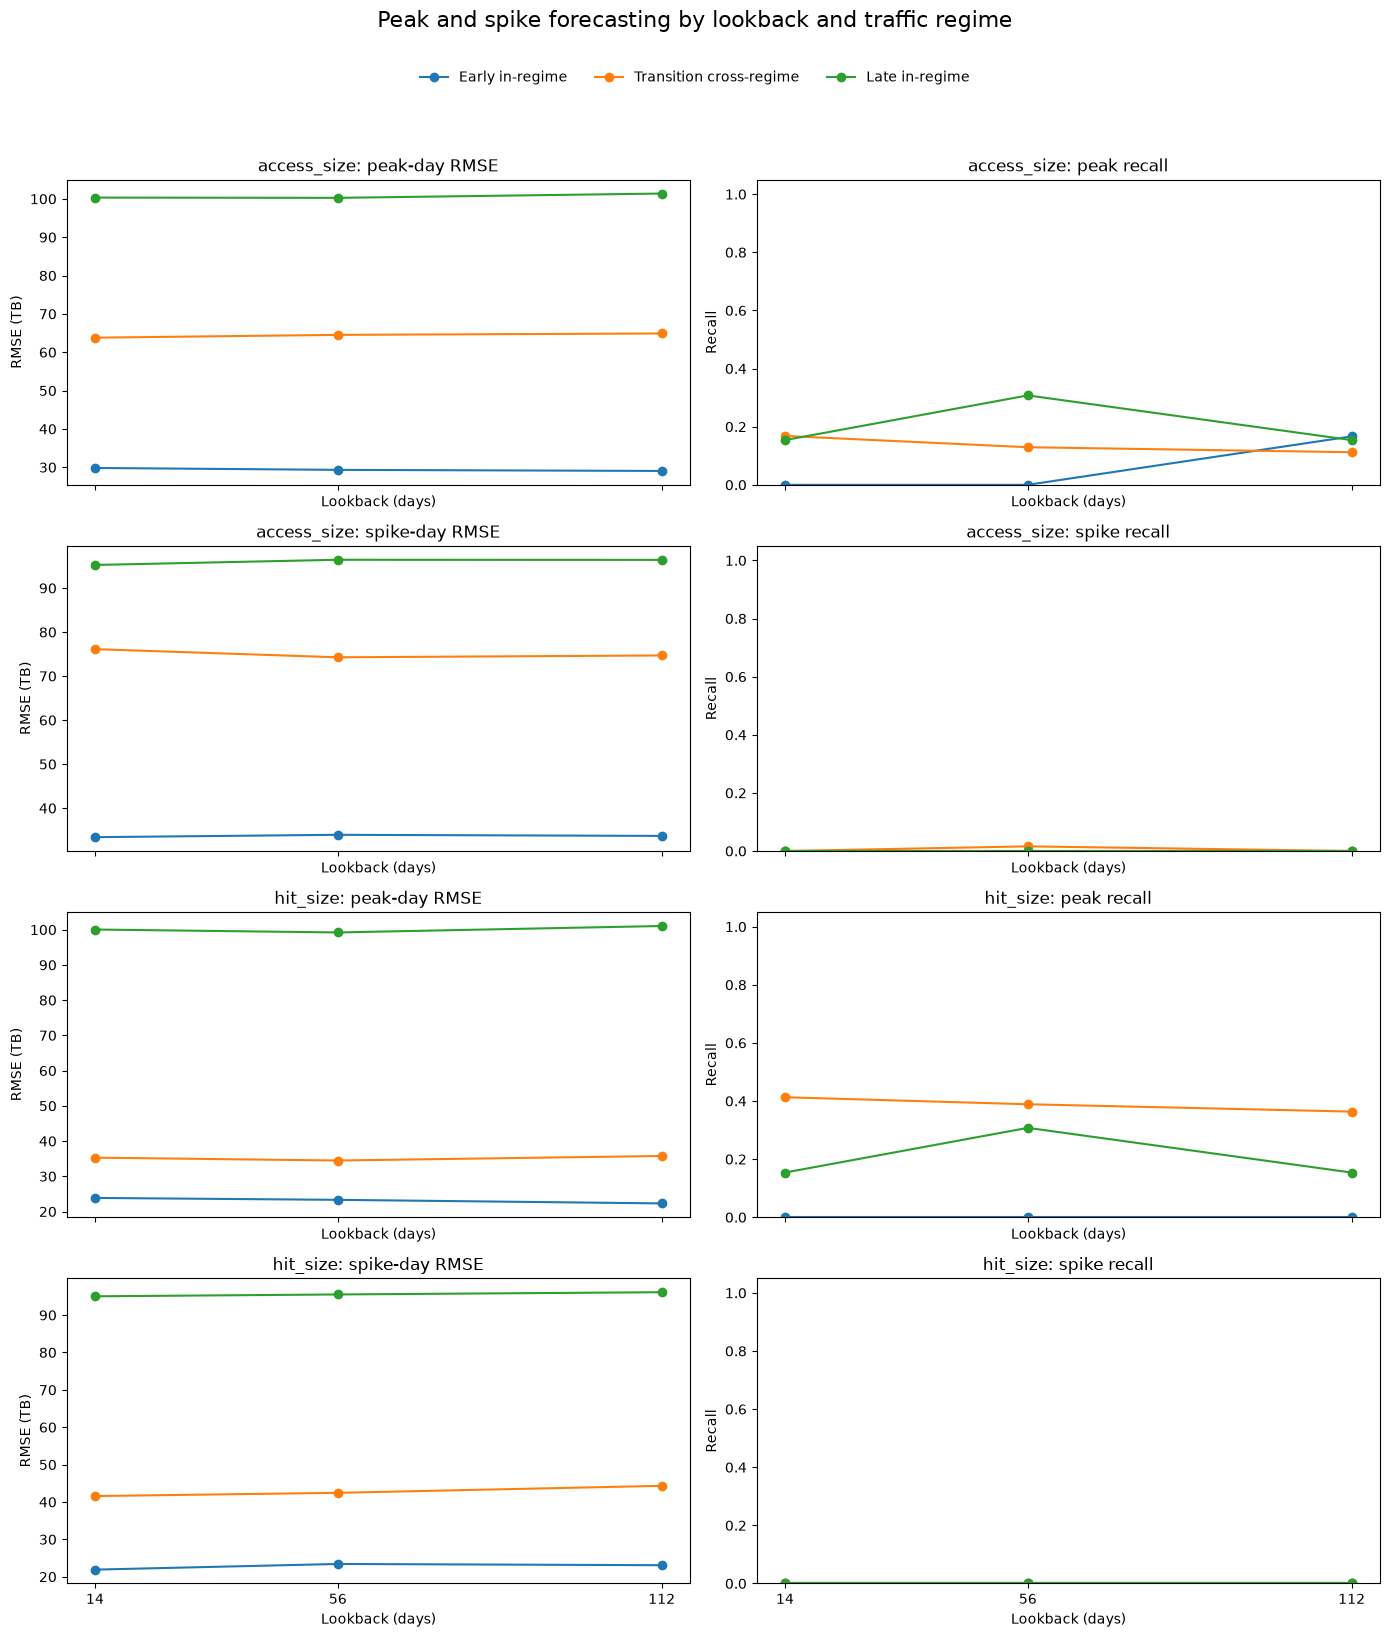

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16), sharex=True)
for variable_index, variable in enumerate(['access_size', 'hit_size']):
    for event_index, event in enumerate(['Peak', 'Spike']):
        row = variable_index * 2 + event_index
        error_rows = stratified_results[(stratified_results['variable'] == variable) & (stratified_results['category'] == event)]
        recall_rows = event_results[(event_results['variable'] == variable) & (event_results['event'] == event)]
        for experiment_name in regimes:
            left = error_rows[error_rows['experiment'] == experiment_name].sort_values('lookback')
            right = recall_rows[recall_rows['experiment'] == experiment_name].sort_values('lookback')
            axes[row, 0].plot(left['lookback'], left['RMSE'], marker='o', label=experiment_name)
            axes[row, 1].plot(right['lookback'], right['recall'], marker='o', label=experiment_name)
        axes[row, 0].set(title=f'{variable}: {event.lower()}-day RMSE', ylabel='RMSE (TB)')
        axes[row, 1].set(title=f'{variable}: {event.lower()} recall', ylabel='Recall', ylim=(0, 1.05))
for axis in axes.flat: axis.set_xlabel('Lookback (days)'); axis.set_xticks(LOOKBACKS)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.99), ncol=3, frameon=False)
fig.suptitle('Peak and spike forecasting by lookback and traffic regime', y=1.02, fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(output_dir / 'peak_and_spike_rmse_and_recall_by_lookback.png', dpi=200, bbox_inches='tight')
plt.show()


### 5. Visualize normal-day, peak-day, and spike-day error

Each panel corresponds to one target variable and one traffic-regime experiment. The lines compare error categories across lookback windows. High RMSE for peak or spike days relative to normal days indicates that the model's overall error is driven by high-utilization events. Bias below zero indicates systematic under-prediction.

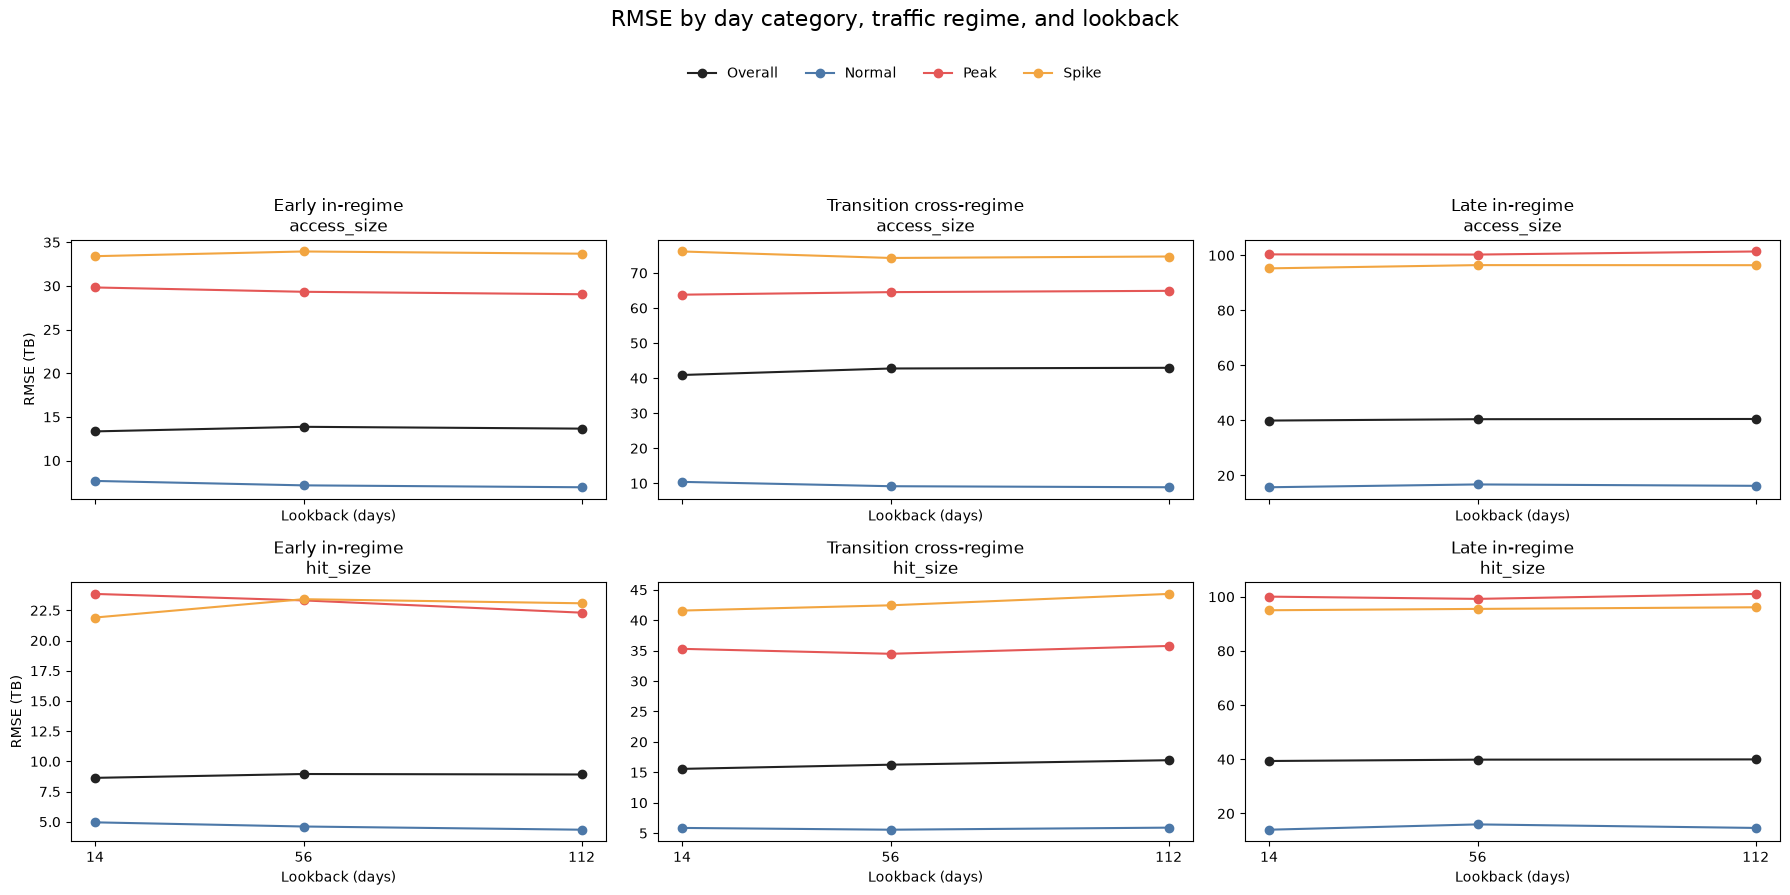

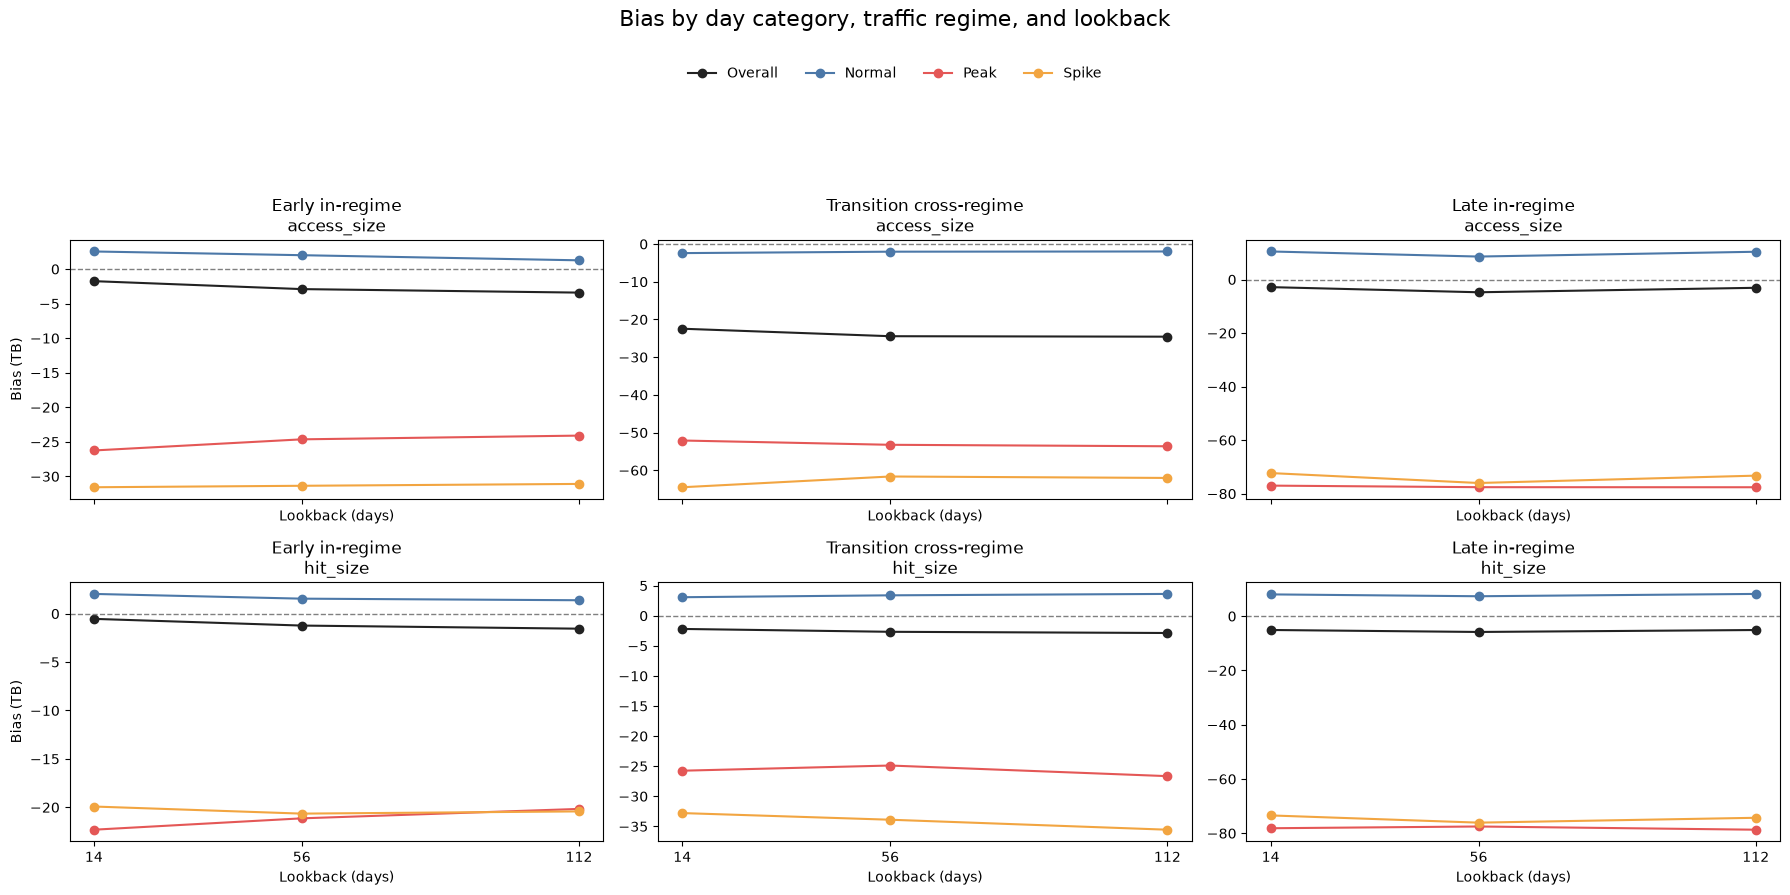

In [9]:
category_order = ['Overall', 'Normal', 'Peak', 'Spike']
category_styles = {'Overall': {'color': '#222222', 'linestyle': '-', 'marker': 'o'}, 'Normal': {'color': '#4c78a8', 'linestyle': '-', 'marker': 'o'}, 'Peak': {'color': '#e45756', 'linestyle': '-', 'marker': 'o'}, 'Spike': {'color': '#f2a541', 'linestyle': '-', 'marker': 'o'}}
experiment_order = ['Early in-regime', 'Transition cross-regime', 'Late in-regime']

def plot_stratified_metric(metric, zero_line=False):
    fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True)
    for row, variable in enumerate(['access_size', 'hit_size']):
        for column, experiment_name in enumerate(experiment_order):
            axis = axes[row, column]
            subset = stratified_results[(stratified_results['variable'] == variable) & (stratified_results['experiment'] == experiment_name)]
            for category in category_order:
                rows = subset[subset['category'] == category].sort_values('lookback')
                axis.plot(rows['lookback'], rows[metric], label=category, **category_styles[category])
            if zero_line: axis.axhline(0, color='gray', linewidth=1, linestyle='--')
            axis.set_title(f'{experiment_name}\n{variable}')
            axis.set_xlabel('Lookback (days)')
            if column == 0: axis.set_ylabel(f'{metric} (TB)')
            axis.set_xticks(LOOKBACKS)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.suptitle(f'{metric} by day category, traffic regime, and lookback', y=0.99, fontsize=16)
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.94), ncol=4, frameon=False)
    fig.tight_layout(rect=[0, 0, 1, 0.84])
    return fig

rmse_figure = plot_stratified_metric('RMSE')
rmse_figure.savefig(output_dir / 'stratified_rmse_by_lookback_and_regime.png', dpi=200, bbox_inches='tight')
plt.show()

bias_figure = plot_stratified_metric('Bias', zero_line=True)
bias_figure.savefig(output_dir / 'stratified_bias_by_lookback_and_regime.png', dpi=200, bbox_inches='tight')
plt.show()
